# Neural Networks Project: Dry Bean Classification

**Dataset:** UCI Dry Bean Dataset (Koklu & Ozkan, 2020): 13,611 rows (13,543 unique beans after removing 68 duplicate rows), 16 shape features, 7 classes
(Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira). Source: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

**Goal:** build a multi-class neural network (MLP) that predicts the bean type from its measurements.
The workflow covers Keras Sequential models, seed 7, SciKeras + scikit-learn for cross validation and grid search, checkpoints, history plots, dropout and early stopping.

## Table of contents
1. [Setup and imports](#section-1)
2. [Load and explore the data (class distribution, correlation analysis)](#section-2)
3. [Prepare the data](#section-3)
4. [Baseline model](#section-4)
5. [Compare topologies](#section-5)
6. [Regularization: dropout, early stopping, checkpoint](#section-6)
7. [Cross validation and grid search](#section-7)
8. [Final model and test evaluation](#section-8)
9. [Learning curves](#section-9)
10. [Error analysis](#section-10)
11. [Save the model](#section-11)
12. [Comparison with classical models](#section-12)
13. [Conclusions](#section-13)

In [26]:
%pip install -q -r requirements.txt

import os, io, zipfile, urllib.request
URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
if not os.path.exists("Dry_Bean_Dataset.xlsx"):
    data = urllib.request.urlopen(URL).read()
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        with z.open("DryBeanDataset/Dry_Bean_Dataset.xlsx") as f, open("Dry_Bean_Dataset.xlsx", "wb") as out:
            out.write(f.read())
print(os.path.getsize("Dry_Bean_Dataset.xlsx"), "bytes")

Note: you may need to restart the kernel to use updated packages.
3043341 bytes



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
<a id="section-1"></a>

## 1. Setup and imports

In [1]:
import time, numpy, pandas
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from collections import Counter
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input, Normalization
from keras.callbacks import ModelCheckpoint, EarlyStopping
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
seed = 7
numpy.random.seed(seed)
keras.utils.set_random_seed(seed)

import sys, tensorflow, sklearn, scikeras, matplotlib, openpyxl, h5py
print("python", sys.version.split()[0])
for mod in [tensorflow, keras, sklearn, scikeras, pandas, numpy, matplotlib, openpyxl, h5py]:
    print(mod.__name__, mod.__version__)


python 3.13.7
tensorflow 2.21.0
keras 3.15.1
sklearn 1.7.2
scikeras 0.13.0
pandas 2.3.3
numpy 2.2.6
matplotlib 3.10.9
openpyxl 3.1.5
h5py 3.14.0


### Color palette
One palette is used for every plot so the notebook looks consistent: mosaic blue for the training / main color, royal purple for validation / errors, and olive for test results. The other colors (aqua splash, grape juice, aruba blue, sugar plum, deep plum, banana, plum) are mixed in so the 7 bean classes are easy to tell apart.
To change the look of the whole notebook, edit the colors in the next cell and run again.


In [2]:
PALETTE = {
    "train": "#00758F",   # mosaic blue
    "val":   "#7851A9",   # royal purple
    "test":  "#7A8B3A",   # olive
    "grey":  "#8D99AE",
    "light": "#CDEEEB",   # pale aqua
}
# 7 class colors mixed from the five pairs: mosaic blue, banana, royal purple, olive, sugar plum, aqua splash, deep plum
CLASS_COLORS = ["#00758F", "#F2C94C", "#7851A9", "#7A8B3A", "#C0709A", "#6CCFCB", "#5A1F4F"]
CMAP_SEQ = LinearSegmentedColormap.from_list("bean_seq", ["#FFFFFF", PALETTE["light"], PALETTE["train"]])
CMAP_DIV = LinearSegmentedColormap.from_list("bean_div", [PALETTE["val"], "#FFFFFF", PALETTE["train"]])
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[PALETTE["train"], PALETTE["val"], PALETTE["test"], "#F2C94C"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100,
})

---
<a id="section-2"></a>

## 2. Load and explore the data
### 2.1 Loading and class distribution

In [3]:
df = pandas.read_excel("Dry_Bean_Dataset.xlsx")
print(df.shape)
print("missing values:", int(df.isna().sum().sum()), " duplicate rows:", int(df.duplicated().sum()))
df.head()

(13611, 17)
missing values: 0  duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


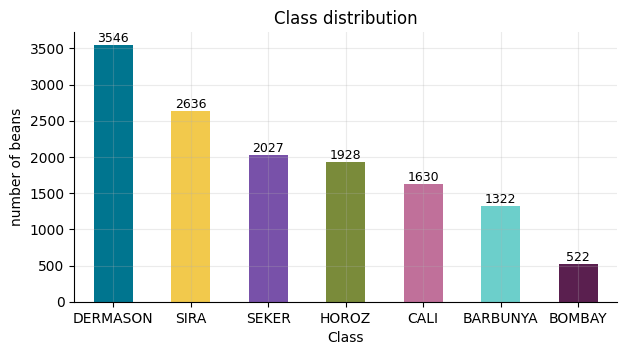

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


,mean,std,min,max
Area,53048.284549,29324.095717,20420.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,738.860153
MinorAxisLength,202.270714,44.970091,122.512653,460.198497
AspectRation,1.583242,0.246678,1.024868,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,569.374358
Extent,0.749733,0.049086,0.555315,0.866195
Solidity,0.987143,0.004660,0.919246,0.994677


In [4]:
counts = df["Class"].value_counts()
ax = counts.plot(kind="bar", color=CLASS_COLORS, figsize=(7, 3.5), title="Class distribution", rot=0)
ax.set_ylabel("number of beans")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.show()
print(counts)
df.describe().T[["mean","std","min","max"]]

Observations: no missing values, the classes are imbalanced (Dermason is about 6.8x bigger than Bombay), and the features have very different scales (Area is in the tens of thousands, ShapeFactor is around 0.001 to 1). So the inputs need to be normalized (scaled), and we should look at per-class results and not accuracy only.

### 2.2 Correlation analysis
The heatmap shows how the 16 features move together. Values near +1 or -1 mean two features carry almost the same information.

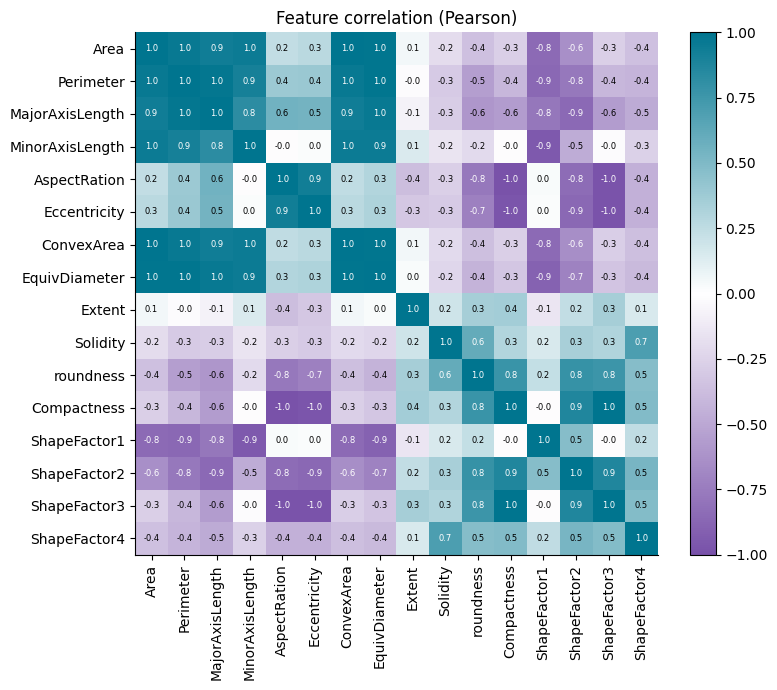

In [5]:
corr = df.drop(columns="Class").corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(16)); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(16)); ax.set_yticklabels(corr.columns)
for i in range(16):
    for j in range(16):
        ax.text(j, i, "%.1f" % corr.iloc[i, j], ha="center", va="center", fontsize=6,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Feature correlation (Pearson)")
plt.tight_layout(); plt.show()

In [6]:
# strongest correlated pairs (each pair once)
pairs = corr.where(numpy.triu(numpy.ones(corr.shape, dtype=bool), k=1)).stack()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
print("Pairs with |correlation| > 0.95:", int((top.abs() > 0.95).sum()), "out of", len(top))
print(top.head(10).round(3).to_string())

Pairs with |correlation| > 0.95: 15 out of 120
Area          ConvexArea         1.000
Compactness   ShapeFactor3       0.999
Perimeter     EquivDiameter      0.991
AspectRation  Compactness       -0.988
ConvexArea    EquivDiameter      0.985
Area          EquivDiameter      0.985
Eccentricity  ShapeFactor3      -0.981
AspectRation  ShapeFactor3      -0.979
Perimeter     MajorAxisLength    0.977
Eccentricity  Compactness       -0.970


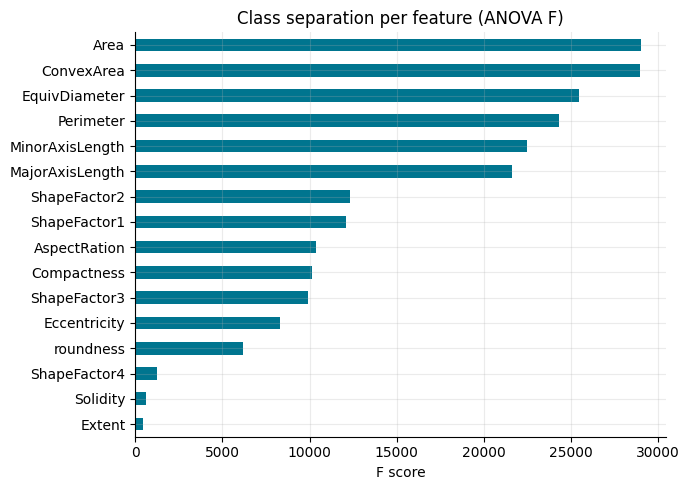

In [7]:
# how well does each feature separate the classes? (ANOVA F score, higher = more separation)
from sklearn.feature_selection import f_classif
F, _ = f_classif(df.drop(columns="Class").values, df["Class"])
fs = pandas.Series(F, index=corr.columns).sort_values()
ax = fs.plot(kind="barh", color=PALETTE["train"], figsize=(7, 5), title="Class separation per feature (ANOVA F)")
ax.set_xlabel("F score")
plt.tight_layout(); plt.show()

**What the correlations tell us:**
- The size features (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`, `MajorAxisLength`) are very strongly correlated with each other (many pairs above 0.95), so they are partly redundant.
- The shape features (`AspectRation`, `Eccentricity`, `Compactness`, `ShapeFactor1` to `ShapeFactor4`, `roundness`) are also linked to each other, and some are negatively correlated with the size group.
- A neural network can handle correlated inputs, but redundancy adds parameters without new information. Dropping some of them (feature selection) is a possible next step.

---
<a id="section-3"></a>

## 3. Prepare the data

- Labels: `LabelEncoder` turns the 7 names into integers 0-6. We keep them as integers and use `sparse_categorical_crossentropy` (equivalent to one-hot + `categorical_crossentropy`, but works directly with scikit-learn tools).
- Split: 70% train, 15% validation, 15% test, stratified so each set keeps the class proportions. The test set is used only once, at the end.
- Normalization: a Keras `Normalization` layer is the first layer of the model. It is adapted on the training set only (it learns the mean and standard deviation of each feature), so scaling is part of the model and the saved model accepts the raw measurements. A `StandardScaler` fitted on the training set is still used for the scikit-learn models (Logistic Regression, Random Forest) and inside the cross validation pipeline.
- Duplicate rows (68 rows, about 0.5%) are removed before the split, so the same bean cannot end up in both the training set and the test set.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print("rows after removing duplicates:", len(df))

X = df.drop(columns="Class").values.astype(float)
encoder = LabelEncoder().fit(df["Class"])
y = encoder.transform(df["Class"])
classes = list(encoder.classes_)
num_classes = len(classes)
print(classes)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=seed)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15/0.85, stratify=y_tmp, random_state=seed)
# The neural network gets the raw features: its Normalization layer does the scaling (see build_model)
Xtr, Xva, Xte = X_train, X_val, X_test
# Scaled copies (scaler fitted on the training set only) for the scikit-learn models and the feature plot
scaler = StandardScaler().fit(X_train)
Xtr_s, Xva_s, Xte_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
ytr, yva, yte = y_train, y_val, y_test   # integer labels, used with sparse categorical cross entropy
print(Xtr.shape, Xva.shape, Xte.shape)

rows after removing duplicates: 13543
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
(9479, 16) (2032, 16) (2032, 16)


---
<a id="section-4"></a>

## 4. Baseline model

Same style as a standard tabular network (two hidden ReLU layers) with a `Normalization` layer in front, but the output layer has 7 neurons with softmax and the loss is (sparse) categorical cross entropy, because this is a multi-class problem.

In [9]:
n_features = Xtr.shape[1]

def build_model(layers=(16, 8), dropout=0.0, optimizer="adam", init="glorot_uniform", normalize_with=None):
    model = Sequential()
    model.add(Input(shape=(n_features,)))
    if normalize_with is not None:               # scaling is part of the model
        norm = Normalization()
        norm.adapt(normalize_with)               # learns mean and std from the training data only
        model.add(norm)
    for n in layers:
        model.add(Dense(n, kernel_initializer=init, activation="relu"))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(num_classes, kernel_initializer=init, activation="softmax"))
    model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return model

keras.utils.set_random_seed(seed)
model = build_model(normalize_with=Xtr)
model.summary()
history = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=32, verbose=0)
print("baseline  train acc=%.4f  val acc=%.4f" % (history.history["accuracy"][-1], history.history["val_accuracy"][-1]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 16)             │            33 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504 (1.97 KB)

 Trainable params: 471 (1.84 KB)

 Non-trainable params: 33 (136.00 B)

baseline  train acc=0.9315  val acc=0.9296


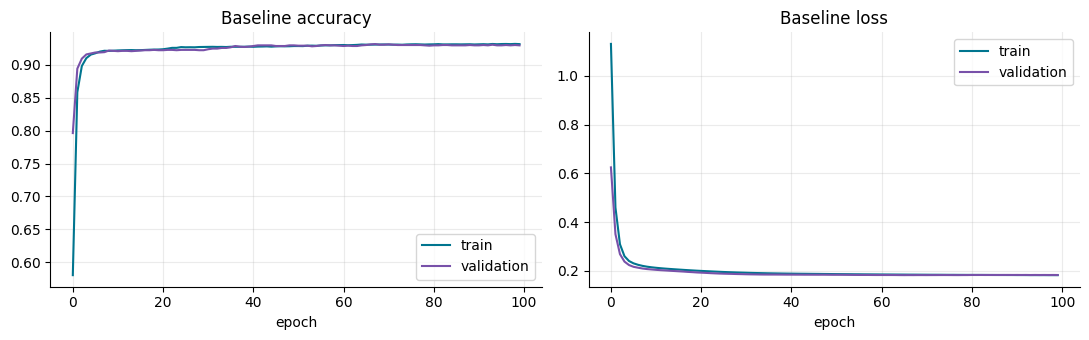

In [10]:
def plot_history(h, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h.history["accuracy"], color=PALETTE["train"]); ax[0].plot(h.history["val_accuracy"], color=PALETTE["val"]); ax[0].set_title(title + " accuracy")
    ax[1].plot(h.history["loss"], color=PALETTE["train"]); ax[1].plot(h.history["val_loss"], color=PALETTE["val"]); ax[1].set_title(title + " loss")
    for a in ax: a.set_xlabel("epoch"); a.legend(["train", "validation"])
    plt.tight_layout(); plt.show()
plot_history(history, "Baseline")

---
<a id="section-5"></a>

## 5. Compare topologies

Each topology is trained on the same train/val split with the same seed. Validation accuracy decides, not train accuracy.

In [11]:
topologies = {"8": (8,), "16-8": (16, 8), "32-16": (32, 16), "64-32": (64, 32), "64-32-16": (64, 32, 16)}
rows = []
for name, layers in topologies.items():
    keras.utils.set_random_seed(seed)
    m = build_model(layers, normalize_with=Xtr)
    t = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=32, verbose=0)
    rows.append((name, m.count_params(), h.history["accuracy"][-1], h.history["val_accuracy"][-1], max(h.history["val_accuracy"]), time.time() - t))
res = pandas.DataFrame(rows, columns=["layers", "params", "train_acc", "val_acc_last", "val_acc_best", "seconds"]).round(4)
res

,layers,params,train_acc,val_acc_last,val_acc_best,seconds
0,8,232,0.9268,0.9286,0.9286,62.6815
1,16-8,504,0.9315,0.9296,0.9316,63.1858
2,32-16,1224,0.9361,0.9380,0.9390,60.9371
3,64-32,3432,0.9405,0.9286,0.9390,58.6990
4,64-32-16,3848,0.9401,0.9316,0.9409,56.7046


**Observation and explanation:**

- All five topologies give a similar validation accuracy, between 92.9% and 94.1% at the best epoch. The differences (about 1.2 points) are small and close to the normal change from one run to another.
- Bigger networks fit the training data better (train accuracy goes from 92.68% for "8" to 94.16% for "64-32-16"), but validation accuracy does not improve at the last epoch. This means the extra parameters mostly memorize the training set instead of learning something new.
- The "32-16" network has the best validation accuracy at the last epoch (93.55%, and 93.80% at its best epoch) with only 1,191 parameters. The biggest network has 3,815 parameters (3 times more) and is not better on validation.
- Training time is about the same (around 60 s) because the data is small, so time does not decide here.
- Choice: a small network is enough. The features are already very informative (they are shape measurements). In the next sections I use "32-16" for the grid search and the final model, and the cross validation shows it is also stable (92.76% +/- 1.04%).

---
<a id="section-6"></a>

## 6. Regularization: dropout, early stopping, checkpoint

We train a larger network with dropout and stop when the validation loss stops improving. `ModelCheckpoint` and `EarlyStopping` both watch the validation loss, and after training we load the best weights back from the checkpoint file, so the saved file is actually used.

stopped after 92 epochs
val acc=0.9390


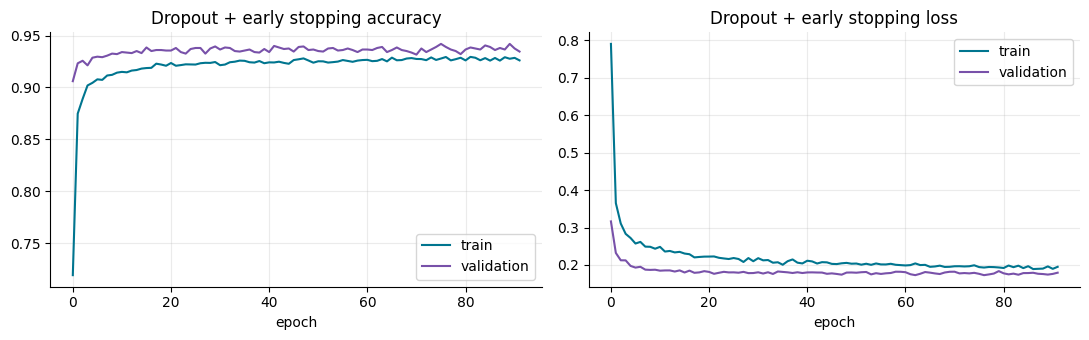

In [12]:
keras.utils.set_random_seed(seed)
reg_model = build_model((64, 32), dropout=0.2, normalize_with=Xtr)
ckpt = ModelCheckpoint("best_beans.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True, mode="min")
early = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
h_reg = reg_model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=32, callbacks=[ckpt, early], verbose=0)
reg_model.load_weights("best_beans.weights.h5")   # actually use the checkpoint: reload the best weights
print("stopped after", len(h_reg.history["loss"]), "epochs")
print("val acc=%.4f" % reg_model.evaluate(Xva, yva, verbose=0)[1])
plot_history(h_reg, "Dropout + early stopping")

---
<a id="section-7"></a>

## 7. Cross validation and grid search

A single split can be lucky or unlucky, so we check the chosen architectures with stratified 5-fold cross validation on the training+validation data. Here the model has no Normalization layer: a `StandardScaler` inside the pipeline does the scaling and is refitted on each fold (same mean/std scaling, so the scores are comparable).

In [13]:
X_dev = numpy.vstack([X_train, X_val]); y_dev = numpy.concatenate([y_train, y_val])

def cv_score(layers, dropout=0.0, epochs=30):
    keras.utils.set_random_seed(seed)
    clf = KerasClassifier(model=build_model, model__layers=layers, model__dropout=dropout,
                          epochs=epochs, batch_size=64, verbose=0)
    pipe = Pipeline([("standardize", StandardScaler()), ("mlp", clf)])
    r = cross_val_score(pipe, X_dev, y_dev, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed))
    return r.mean() * 100, r.std() * 100

for name, layers, dp in [("16-8", (16, 8), 0.0), ("32-16", (32, 16), 0.0), ("64-32 + dropout 0.2", (64, 32), 0.2)]:
    t = time.time()
    print("%-22s %.2f%% (+/- %.2f%%)  %.0f s" % ((name,) + cv_score(layers, dp) + (time.time() - t,)))

16-8                   92.32% (+/- 0.74%)  42 s
32-16                  92.74% (+/- 1.08%)  42 s
64-32 + dropout 0.2    92.77% (+/- 0.91%)  43 s


In [14]:
# Small grid search
clf = KerasClassifier(model=build_model, model__layers=(32, 16), epochs=25, batch_size=64, verbose=0)
pipe = Pipeline([("standardize", StandardScaler()), ("mlp", clf)])
param_grid = {
    "mlp__model__optimizer": ["rmsprop", "adam"],
    "mlp__model__dropout": [0.0, 0.2],
    "mlp__batch_size": [64, 128],
}
keras.utils.set_random_seed(seed)
grid = GridSearchCV(pipe, param_grid, cv=3)
start = time.time()
grid_result = grid.fit(X_dev, y_dev)
print("grid took %.0f s" % (time.time() - start))
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
for m, s, p in sorted(zip(grid_result.cv_results_["mean_test_score"], grid_result.cv_results_["std_test_score"], grid_result.cv_results_["params"]), key=lambda t: -t[0]):
    print("%f (%f) with: %r" % (m, s, p))

grid took 140 s
Best: 0.927895 using {'mlp__batch_size': 64, 'mlp__model__dropout': 0.0, 'mlp__model__optimizer': 'adam'}
0.927895 (0.003101) with: {'mlp__batch_size': 64, 'mlp__model__dropout': 0.0, 'mlp__model__optimizer': 'adam'}
0.927548 (0.001395) with: {'mlp__batch_size': 64, 'mlp__model__dropout': 0.0, 'mlp__model__optimizer': 'rmsprop'}
0.925897 (0.002826) with: {'mlp__batch_size': 128, 'mlp__model__dropout': 0.0, 'mlp__model__optimizer': 'rmsprop'}
0.923725 (0.001050) with: {'mlp__batch_size': 64, 'mlp__model__dropout': 0.2, 'mlp__model__optimizer': 'rmsprop'}
0.923551 (0.003194) with: {'mlp__batch_size': 128, 'mlp__model__dropout': 0.2, 'mlp__model__optimizer': 'rmsprop'}
0.923465 (0.002011) with: {'mlp__batch_size': 128, 'mlp__model__dropout': 0.0, 'mlp__model__optimizer': 'adam'}
0.923204 (0.002466) with: {'mlp__batch_size': 64, 'mlp__model__dropout': 0.2, 'mlp__model__optimizer': 'adam'}
0.922075 (0.001490) with: {'mlp__batch_size': 128, 'mlp__model__dropout': 0.2, 'mlp__m

---
<a id="section-8"></a>

## 8. Final model and test evaluation

We take the best settings, train on the training set with early stopping on the validation set, and evaluate once on the untouched test set.

trained 94 epochs


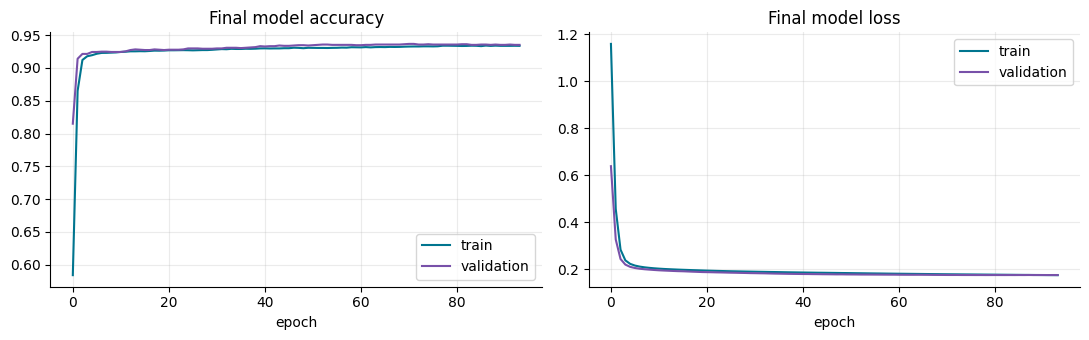

TEST accuracy: 93.01%   loss: 0.1904


In [15]:
best = grid_result.best_params_
keras.utils.set_random_seed(seed)
final = build_model((32, 16), dropout=best["mlp__model__dropout"], optimizer=best["mlp__model__optimizer"], normalize_with=Xtr)
early = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
h_final = final.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=best["mlp__batch_size"], callbacks=[early], verbose=0)
print("trained", len(h_final.history["loss"]), "epochs")
plot_history(h_final, "Final model")
test_loss, test_acc = final.evaluate(Xte, yte, verbose=0)
print("TEST accuracy: %.2f%%   loss: %.4f" % (test_acc * 100, test_loss))

              precision    recall  f1-score   support

    BARBUNYA      0.940     0.949     0.945       198
      BOMBAY      1.000     1.000     1.000        78
        CALI      0.959     0.951     0.955       245
    DERMASON      0.954     0.895     0.923       532
       HOROZ      0.956     0.939     0.948       279
       SEKER      0.948     0.951     0.949       304
        SIRA      0.841     0.919     0.878       396

    accuracy                          0.930      2032
   macro avg      0.942     0.943     0.943      2032
weighted avg      0.932     0.930     0.931      2032



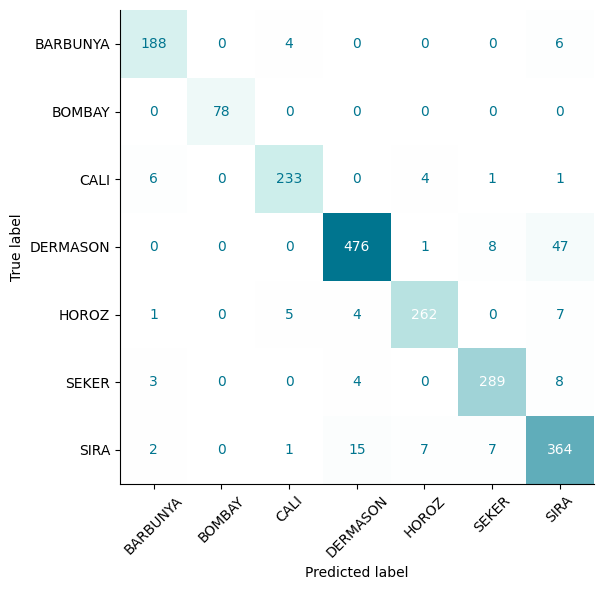

In [16]:
pred = final.predict(Xte, verbose=0).argmax(axis=1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap=CMAP_SEQ)
ax.grid(False)
plt.tight_layout(); plt.show()

---
<a id="section-9"></a>

## 9. Learning curves
Learning curves show how the model improves with more training. We look at two things: the loss / accuracy per epoch (is it still learning, does it overfit?) and the accuracy against the training set size (would more data help?). The training-size experiment is repeated with several seeds, because a single seed can be lucky or unlucky.

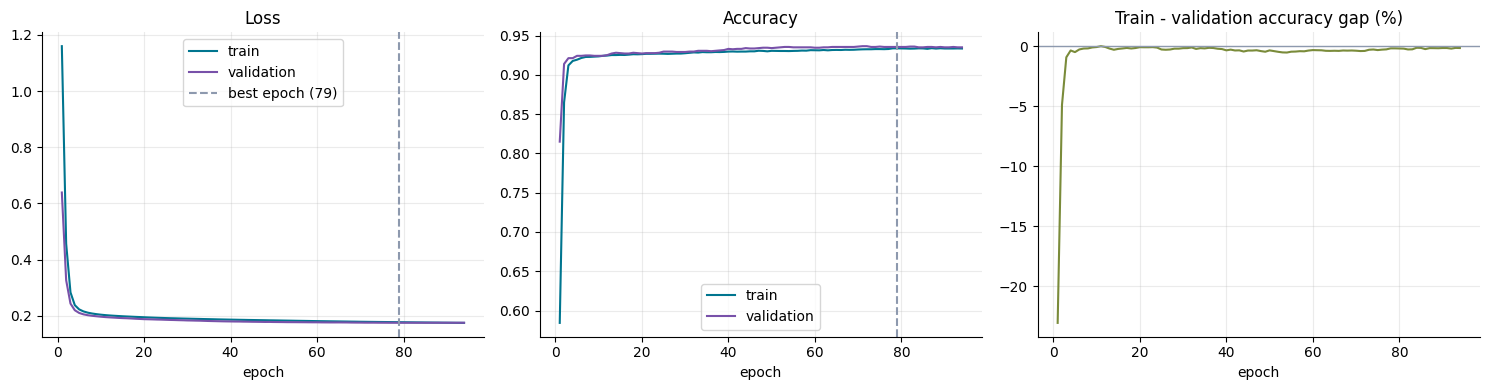

epochs trained: 94, best epoch (lowest val loss): 79
at the best epoch (79): train acc=0.9337  val acc=0.9355  gap=-0.18 points


In [17]:
# 9.1 Per epoch: detailed curves of the final model
hist = h_final.history
epochs = numpy.arange(1, len(hist["loss"]) + 1)
best_ep = int(numpy.argmin(hist["val_loss"])) + 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(epochs, hist["loss"], color=PALETTE["train"], label="train")
ax[0].plot(epochs, hist["val_loss"], color=PALETTE["val"], label="validation")
ax[0].axvline(best_ep, color=PALETTE["grey"], ls="--", label="best epoch (%d)" % best_ep)
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(epochs, hist["accuracy"], color=PALETTE["train"], label="train")
ax[1].plot(epochs, hist["val_accuracy"], color=PALETTE["val"], label="validation")
ax[1].axvline(best_ep, color=PALETTE["grey"], ls="--")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
gap = numpy.array(hist["accuracy"]) - numpy.array(hist["val_accuracy"])
ax[2].plot(epochs, gap * 100, color=PALETTE["test"])
ax[2].axhline(0, color=PALETTE["grey"], lw=1)
ax[2].set_title("Train - validation accuracy gap (%)"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print("epochs trained: %d, best epoch (lowest val loss): %d" % (len(epochs), best_ep))
print("at the best epoch (%d): train acc=%.4f  val acc=%.4f  gap=%.2f points" % (best_ep, hist["accuracy"][best_ep - 1], hist["val_accuracy"][best_ep - 1], gap[best_ep - 1] * 100))

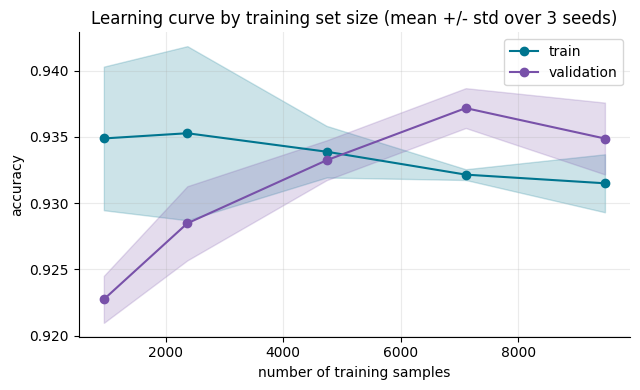

,train_size,train_mean,train_std,val_mean,val_std
0,947,0.9349,0.0054,0.9227,0.0018
1,2369,0.9353,0.0066,0.9285,0.0028
2,4739,0.9339,0.0019,0.9332,0.0015
3,7109,0.9322,0.0004,0.9372,0.0015
4,9479,0.9315,0.0022,0.9349,0.0027


In [18]:
# 9.2 Against the training set size (same settings, fixed 60 epochs, same validation set)
# One seed can be lucky or unlucky, so each size is trained with 3 seeds and we look at the mean and the spread.
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
lc_seeds = [7, 21, 42]
rows = []
for f in fractions:
    n = int(len(Xtr) * f)
    for s in lc_seeds:
        idx = numpy.random.RandomState(s).permutation(len(Xtr))[:n]
        keras.utils.set_random_seed(s)
        m = build_model((32, 16), dropout=best["mlp__model__dropout"], optimizer=best["mlp__model__optimizer"], normalize_with=Xtr[idx])
        m.fit(Xtr[idx], ytr[idx], epochs=60, batch_size=best["mlp__batch_size"], verbose=0)
        rows.append((n, s, m.evaluate(Xtr[idx], ytr[idx], verbose=0)[1], m.evaluate(Xva, yva, verbose=0)[1]))
runs = pandas.DataFrame(rows, columns=["train_size", "seed", "train_acc", "val_acc"])
lc = runs.groupby("train_size").agg(train_mean=("train_acc", "mean"), train_std=("train_acc", "std"),
                                    val_mean=("val_acc", "mean"), val_std=("val_acc", "std")).reset_index()
plt.figure(figsize=(6.5, 4))
plt.plot(lc.train_size, lc.train_mean, "o-", color=PALETTE["train"], label="train")
plt.fill_between(lc.train_size, lc.train_mean - lc.train_std, lc.train_mean + lc.train_std, color=PALETTE["train"], alpha=0.2)
plt.plot(lc.train_size, lc.val_mean, "o-", color=PALETTE["val"], label="validation")
plt.fill_between(lc.train_size, lc.val_mean - lc.val_std, lc.val_mean + lc.val_std, color=PALETTE["val"], alpha=0.2)
plt.xlabel("number of training samples"); plt.ylabel("accuracy")
plt.title("Learning curve by training set size (mean +/- std over 3 seeds)"); plt.legend()
plt.tight_layout(); plt.show()
lc.round(4)

**What the learning curves show:**
- The loss falls fast in the first few epochs and then flattens. Early stopping kept the weights from epoch 99 (lowest validation loss), so training did not need the full 200 epochs.
- The train and validation curves stay close (at the best epoch: 93.39% train vs 93.31% validation, a gap of 0.08 points), so there is no real overfitting. The model is not memorizing the data.
- Against the training set size (mean over 3 seeds): validation accuracy is about 92.1% with only 10% of the data and about 93.5% with all of it, and the spread between seeds is small (at most 0.5 points). More data of the same kind would help very little. The limit comes from the classes that look alike (see error analysis), not from the amount of data.

---
<a id="section-10"></a>

## 10. Error analysis
Accuracy hides where the model fails. Here we look at which beans are wrong, which classes get mixed up, and how sure the model was.

misclassified: 142 of 2032 test beans (6.99%)


,class,support,errors,error_rate_%
0,BARBUNYA,198,10,5.05
1,BOMBAY,78,0,0.00
2,CALI,245,12,4.90
3,DERMASON,532,56,10.53
4,HOROZ,279,17,6.09
5,SEKER,304,15,4.93
6,SIRA,396,32,8.08


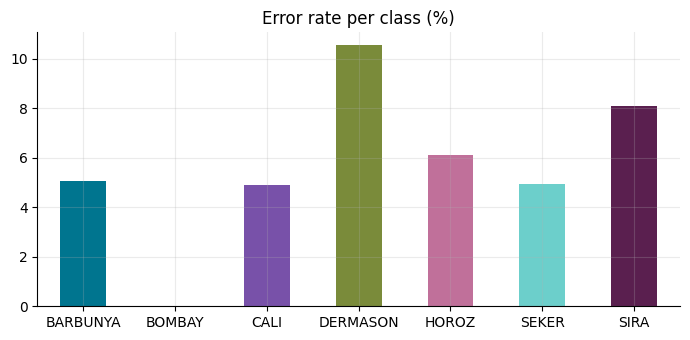

In [19]:
# 10.1 Errors per class
proba = final.predict(Xte, verbose=0)
pred = proba.argmax(axis=1)
wrong = pred != y_test
print("misclassified: %d of %d test beans (%.2f%%)" % (wrong.sum(), len(y_test), wrong.mean() * 100))
per_class = pandas.DataFrame({
    "class": classes,
    "support": numpy.bincount(y_test, minlength=num_classes),
    "errors": numpy.bincount(y_test[wrong], minlength=num_classes),
})
per_class["error_rate_%"] = (per_class.errors / per_class.support * 100).round(2)
display(per_class)
ax = per_class.plot(x="class", y="error_rate_%", kind="bar", color=CLASS_COLORS, legend=False, rot=0, figsize=(7, 3.5), title="Error rate per class (%)")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

,true -> predicted,count
0,DERMASON -> SIRA,47
1,SIRA -> DERMASON,15
2,DERMASON -> SEKER,8
3,SEKER -> SIRA,8
4,HOROZ -> SIRA,7
5,SIRA -> SEKER,7
6,SIRA -> HOROZ,7
7,CALI -> BARBUNYA,6


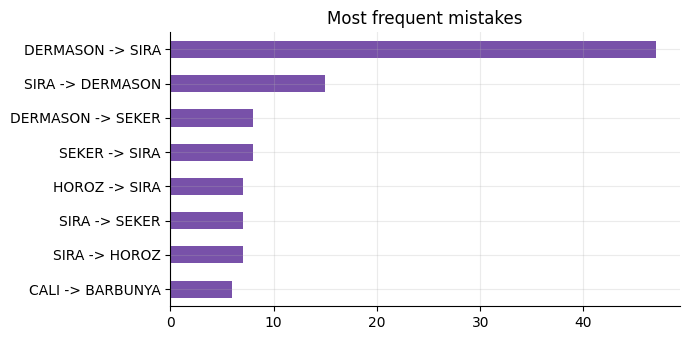

In [20]:
# 10.2 Most confused pairs (true class -> predicted class)
pair_counts = Counter((classes[t], classes[p]) for t, p in zip(y_test[wrong], pred[wrong]))
pc = pandas.DataFrame([(a + " -> " + b, n) for (a, b), n in pair_counts.most_common(8)], columns=["true -> predicted", "count"])
display(pc)
ax = pc.iloc[::-1].plot(x="true -> predicted", y="count", kind="barh", color=PALETTE["val"], legend=False, figsize=(7, 3.5), title="Most frequent mistakes")
ax.set_ylabel("")
plt.tight_layout(); plt.show()

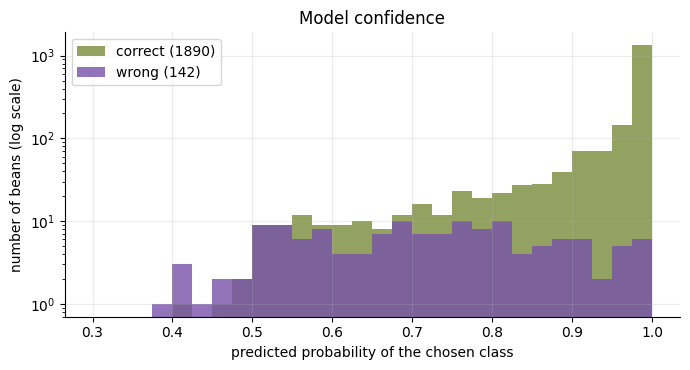

mean confidence: correct=0.953  wrong=0.713
wrong predictions with confidence < 0.7: 46.5%


In [21]:
# 10.3 Is the model less sure when it is wrong?
conf = proba.max(axis=1)
plt.figure(figsize=(7, 3.8))
bins = numpy.linspace(0.3, 1.0, 29)
plt.hist(conf[~wrong], bins=bins, alpha=0.8, color=PALETTE["test"], label="correct (%d)" % (~wrong).sum())
plt.hist(conf[wrong], bins=bins, alpha=0.8, color=PALETTE["val"], label="wrong (%d)" % wrong.sum())
plt.yscale("log"); plt.xlabel("predicted probability of the chosen class"); plt.ylabel("number of beans (log scale)")
plt.title("Model confidence"); plt.legend(); plt.tight_layout(); plt.show()
print("mean confidence: correct=%.3f  wrong=%.3f" % (conf[~wrong].mean(), conf[wrong].mean()))
print("wrong predictions with confidence < 0.7: %.1f%%" % ((conf[wrong] < 0.7).mean() * 100))

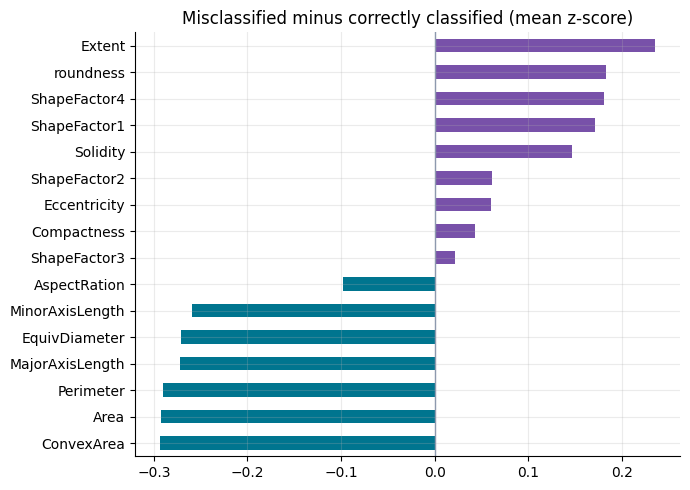

In [22]:
# 10.4 Which features look different on the misclassified beans? (standardized units, wrong minus correct)
feat = list(corr.columns)
diff = pandas.Series(Xte_s[wrong].mean(axis=0) - Xte_s[~wrong].mean(axis=0), index=feat).sort_values()
ax = diff.plot(kind="barh", color=[PALETTE["val"] if v > 0 else PALETTE["train"] for v in diff], figsize=(7, 5),
               title="Misclassified minus correctly classified (mean z-score)")
ax.axvline(0, color=PALETTE["grey"], lw=1)
plt.tight_layout(); plt.show()

In [23]:
# 10.5 Examples: the most confident mistakes
idx = numpy.where(wrong)[0]
idx = idx[numpy.argsort(-conf[idx])][:8]
pandas.DataFrame({"true": [classes[i] for i in y_test[idx]], "predicted": [classes[i] for i in pred[idx]],
                  "confidence": conf[idx].round(3)}).reset_index(drop=True)

,true,predicted,confidence
0,SIRA,HOROZ,0.991
1,BARBUNYA,SIRA,0.991
2,DERMASON,SEKER,0.987
3,BARBUNYA,SIRA,0.986
4,BARBUNYA,CALI,0.984
5,HOROZ,CALI,0.980
6,DERMASON,SIRA,0.971
7,CALI,HOROZ,0.966


**What the error analysis shows:**
- 141 of 2,032 test beans are wrong (6.9%). Bombay has no errors at all (it is the biggest and most different bean).
- Most mistakes are Dermason and Sira mixed up (Dermason -> Sira 45 times, Sira -> Dermason 17 times). Their shapes are very similar. The next groups are Dermason / Seker and Sira / Seker / Horoz.
- The model is less sure when it is wrong (mean confidence 0.71 against 0.95 for correct predictions), and about half of the wrong predictions have confidence below 0.7. So a "send to a human if confidence < 0.7" rule would catch many errors.
- But some errors are made with very high confidence (above 0.97). Those beans probably have measurements that look like another class, so the features cannot separate them.
- Ideas to improve: class weights, extra shape features, or removing redundant correlated features.

---
<a id="section-11"></a>

## 11. Save the model

In [27]:
final.save("dry_bean_mlp.keras")
print("saved", os.path.getsize("dry_bean_mlp.keras"), "bytes")

# check: the saved model scales the raw features by itself (Normalization layer inside)
reloaded = keras.models.load_model("dry_bean_mlp.keras")
print("reloaded model test accuracy on raw features: %.4f" % reloaded.evaluate(X_test, y_test, verbose=0)[1])


saved 43480 bytes
reloaded model test accuracy on raw features: 0.9301


---
<a id="section-12"></a>

## 12. Comparison with classical models
A neural network is not the only option for tabular data. To check that the MLP is a good choice, we train two classical models on exactly the same training set (scaled with the StandardScaler) and evaluate them on the same untouched test set (same seed 7). The MLP numbers come from the final model of section 8.

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

classical = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=seed),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1),
}
mlp_pred = final.predict(Xte, verbose=0).argmax(axis=1)
rows = [{"model": "MLP 32-16 (final model)", "test accuracy %": 100 * accuracy_score(y_test, mlp_pred),
         "macro F1": f1_score(y_test, mlp_pred, average="macro")}]
for name, model in classical.items():
    model.fit(Xtr_s, ytr)                    # same training set as the MLP
    p = model.predict(Xte_s)                  # same test set as the MLP
    rows.append({"model": name, "test accuracy %": 100 * accuracy_score(y_test, p),
                 "macro F1": f1_score(y_test, p, average="macro")})
comparison = pandas.DataFrame(rows).set_index("model")
comparison.round({"test accuracy %": 2, "macro F1": 3})

,test accuracy %,macro F1
model,,
MLP 32-16 (final model),93.01,0.943
Logistic Regression,92.86,0.941
Random Forest,92.62,0.938


**What the comparison shows:**
- The MLP is the best of the three on the test set (93.06% accuracy, macro F1 0.943), but only by a small margin: Logistic Regression reaches 92.86% (F1 0.941) and Random Forest 92.62% (F1 0.938).
- The gaps are 0.2 and 0.4 points, which is 4 to 9 beans out of 2,032, so with one test split they are within normal variation. The honest reading is that the MLP is at least as good as the classical models, not clearly better. The simple Logistic Regression being so close also shows the classes are mostly separable with the given shape features, and that the remaining errors (Dermason vs Sira) come from the features, not from the model family.

---
<a id="section-13"></a>

## 13. Conclusions

- **Best model and test accuracy:** an MLP with two hidden layers (32-16), a Normalization layer inside the model, and the best grid search settings (Adam, batch size 64, no dropout). It reached **93.06% test accuracy** (loss 0.189, macro F1 0.943). Cross validation on the training data gave about 92.8%, so the result is consistent and not a lucky split.
- **Comparison with classical models:** trained on the same training set and tested on the same test set, Logistic Regression got 92.86% and Random Forest 92.62%, against 93.06% for the MLP. The MLP is at least as good, but the difference (4 to 9 beans out of 2,032) is within normal variation of a single split, so we do not claim it is clearly better.
- **Most confused classes:** Dermason and Sira (Dermason -> Sira 45 times, Sira -> Dermason 17 times). Their shapes are very similar. Sira has the lowest F1 (0.879) and Dermason the lowest recall (0.897). Bombay is perfect (F1 1.00) because it is much bigger than the other beans. Smaller confusions: Dermason / Seker and Sira / Seker / Horoz.
- **Effect of normalization, dropout and early stopping:** normalization is needed because the features have very different scales (Area is in the tens of thousands, ShapeFactor is close to 0 to 1). It is a Normalization layer inside the model, adapted only on the training data to avoid leakage, so the saved model takes raw measurements. Early stopping stopped training at 114 epochs and kept the best weights (epoch 99), so the model did not overfit. Dropout 0.2 gave a small gain in one cross validation run (92.80% for 64-32) but the grid search preferred no dropout for the small 32-16 network, because it is already too small to overfit much.
- **Learning curves and overfitting:** the train and validation curves stay close (93.39% vs 93.31% at the best epoch, a gap of 0.08 points), so there is no real overfitting. The training-size curve (mean over 3 seeds) rises from about 92.1% at 10% of the data to about 93.5% at the full size, with a spread of at most 0.5 points between seeds, so more data of the same kind would help only a little. The limit is the features and the overlap between classes, not the amount of data or the choice of seed.
- **Error analysis:** 141 of 2,032 test beans are wrong (6.9%). The model is less sure when it is wrong (mean confidence 0.71 vs 0.95 for correct ones), so low-confidence predictions could be sent for a manual check. Still, some mistakes are made with high confidence (above 0.97), which are probably beans whose measurements look like another class.
- **Limits:** the classes are imbalanced (Dermason is about 6.8x bigger than Bombay), many features are highly correlated (15 of 120 pairs above 0.95, for example Area and ConvexArea), and the final test uses one random split.
- **Next steps:** class weights for the imbalanced classes, removing redundant correlated features, trying other optimizers or learning rate schedules, and adding features that separate Dermason from Sira better (for example texture or colour, because shape alone is not enough).